300
(424, 640, 4)


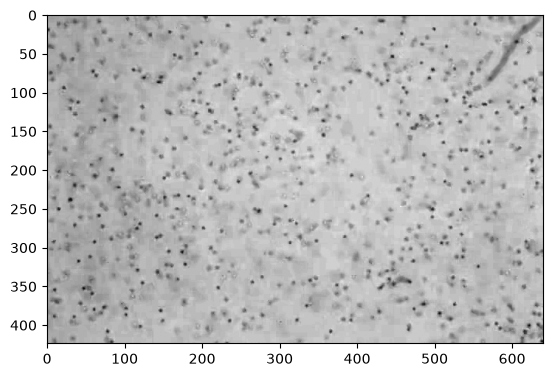

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
from pandas import DataFrame, Series

import pims
import trackpy as tp

frames_bulk_water = pims.open(
    '/home/susanta/Downloads/trackpy-examples/sample_data/bulk_water/*.png'
)

print(frames_bulk_water.__len__())
print(frames_bulk_water.frame_shape)

@pims.pipeline
def gray(image):
    return image[:, :, 1]

frames = gray(frames_bulk_water)

plt.imshow(frames[0], cmap='gray')
plt.show()

In [2]:
f = tp.locate(frames[0], 11, invert=True)
f.head()

,y,x,mass,size,ecc,signal,raw_mass,ep,frame
0,4.750000,103.668564,192.862485,2.106615,0.066390,10.808405,10714.0,0.073666,0
1,5.249231,585.779487,164.659302,2.962674,0.078936,4.222033,10702.0,0.075116,0
2,5.785986,294.792544,244.624615,2.244542,0.219217,15.874846,10686.0,0.077141,0
3,5.869369,338.173423,187.458282,2.046201,0.185333,13.088304,10554.0,0.099201,0
4,6.746377,310.584169,151.486558,3.103294,0.053342,4.475355,10403.0,0.147430,0


mass = intensity 

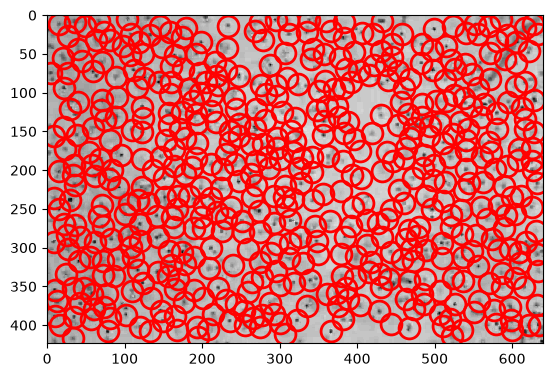

In [3]:
tp.annotate(f, frames[0])
plt.show()


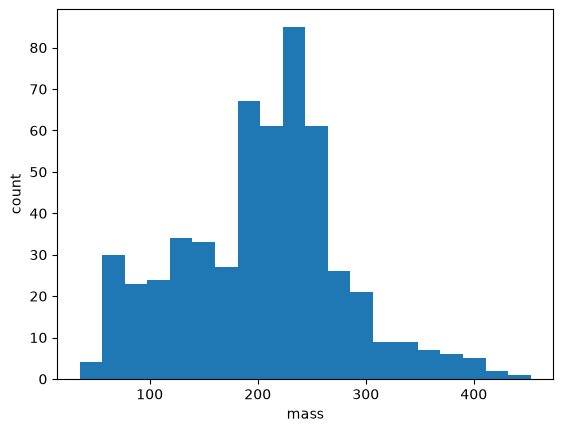

In [4]:
fig, ax = plt.subplots()
ax.hist(f['mass'], bins=20)
ax.set(xlabel='mass', ylabel='count')
plt.show()

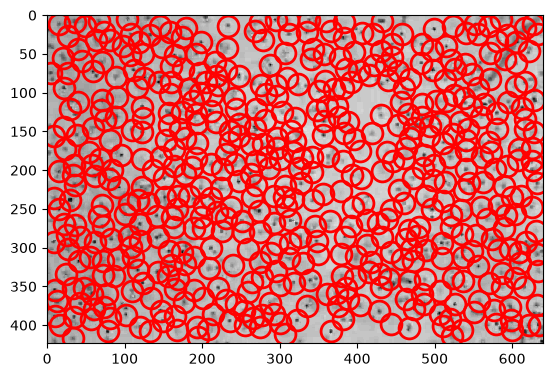

In [5]:
f = tp.locate(frames[0], 11, invert=True, minmass=20)
tp.annotate(f, frames[0])
plt.show()

In [16]:
f = tp.batch(frames[:300], 11, minmass=20, invert=True)

Frame 299: 624 features


In [24]:
t = tp.link(f, 5, memory=3)
t.head(5)

Frame 299: 624 trajectories present.


,y,x,mass,size,ecc,signal,raw_mass,ep,frame,particle
0,4.750000,103.668564,192.862485,2.106615,0.066390,10.808405,10714.0,0.073666,0,0
1,5.249231,585.779487,164.659302,2.962674,0.078936,4.222033,10702.0,0.075116,0,1
2,5.785986,294.792544,244.624615,2.244542,0.219217,15.874846,10686.0,0.077141,0,2
3,5.869369,338.173423,187.458282,2.046201,0.185333,13.088304,10554.0,0.099201,0,3
4,6.746377,310.584169,151.486558,3.103294,0.053342,4.475355,10403.0,0.147430,0,4


In [25]:
len(t[t['frame'] == 299])

624

In [20]:
t['particle'].nunique()


13715

In [11]:
t1 = tp.filter_stubs(t, 25)

# Compare the number of particles before and after filtering
print(f"Number of particles before filtering: {t['particle'].nunique()}")
print(f"Number of particles after filtering: {t1['particle'].nunique()}")

Number of particles before filtering: 13715
Number of particles after filtering: 1505


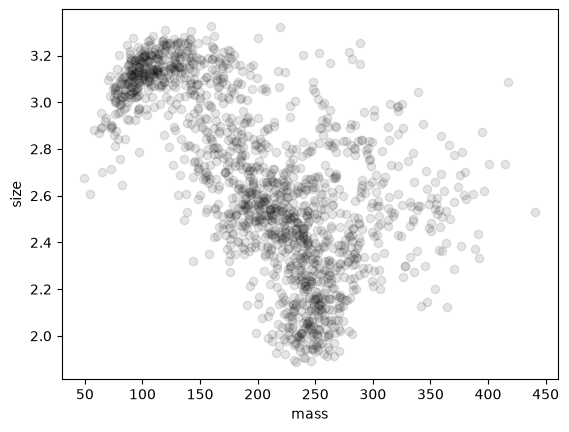

In [9]:
plt.figure()
tp.mass_size(t1.groupby('particle').mean())
plt.show()

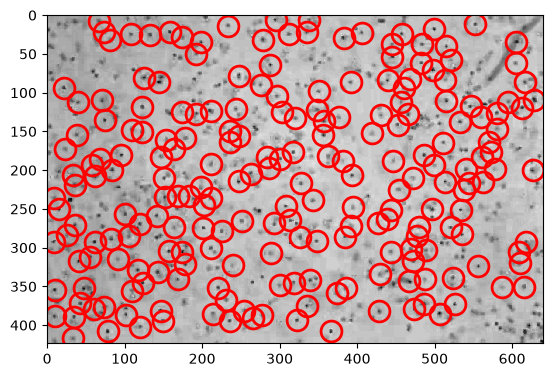

In [22]:
t2 = t1[((t1['mass'] > 50) & (t1['size'] < 2.6) 
         & (t1['ecc'] < 0.3))]

plt.figure()
tp.annotate(t2[t2['frame'] == 0], frames[0])
plt.show()

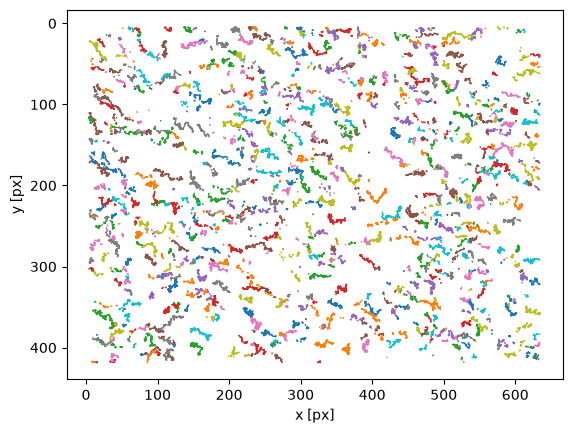

In [23]:
plt.figure()
tp.plot_traj(t2)
plt.show()

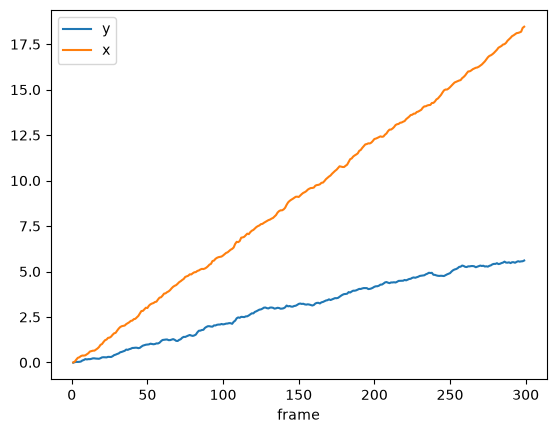

In [24]:
d = tp.compute_drift(t2)
d.plot()
plt.show()

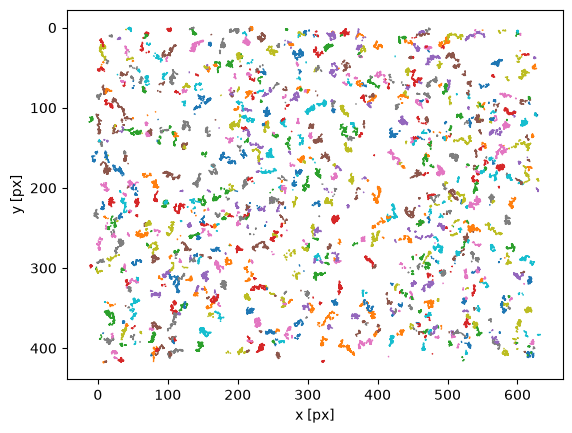

In [26]:
tm = tp.subtract_drift(t2.copy(), d)

ax = tp.plot_traj(tm)
ax.set_title('Drift-subtracted trajectories')
plt.show()

In [ ]:
im = tp.imsd(tm, 100/285., 24)

fig, ax = plt.subplots()
ax.plot(im.index, im, 'k-', alpha=0.1)
ax.set(ylabel=r'$\langle \Delta r^2 \rangle$ [$\mu$m$^2$]',
       xlabel='lag time $t$')
ax.set_xscale('log')
ax.set_yscale('log')

plt.show()

Ensemble Mean Squared Displacement 

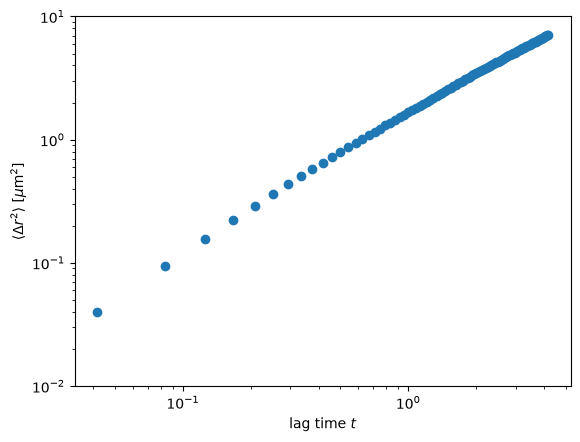

In [53]:
em = tp.emsd(tm, 100/285., 24)

fig, ax = plt.subplots()
ax.plot(em.index, em, 'o')
ax.set_xscale('log')
ax.set_yscale('log')

ax.set(ylabel=r'$\langle \Delta r^2 \rangle$ [$\mu$m$^2$]',
       xlabel='lag time $t$')
ax.set(ylim=(1e-2, 10));

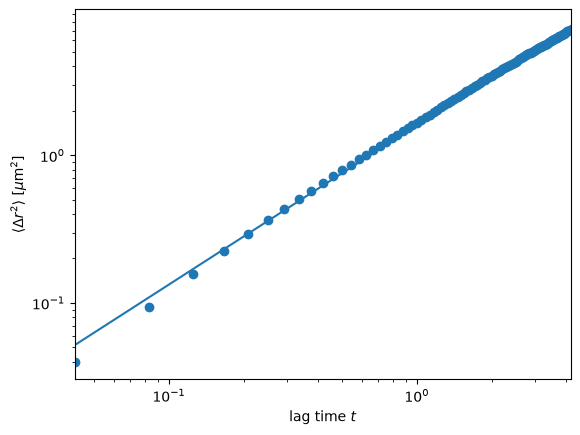

,n,A
msd,1.08024,1.602365


In [ ]:
plt.figure()
plt.ylabel(r'$\langle \Delta r^2 \rangle$ [$\mu$m$^2$]')
plt.xlabel('lag time $t$')
tp.utils.fit_powerlaw(em)

